In [ ]:
!pip install -q umap-learn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.cluster import KMeans, DBSCAN, SpectralClustering

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
    davies_bouldin_score
)

import umap.umap_ as umap

import warnings
warnings.filterwarnings("ignore")

In [ ]:
mnist = fetch_openml(
    'mnist_784',
    version=1,
    as_frame=False
)

X = mnist.data
y = mnist.target.astype(int)

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (70000, 784)
Target shape: (70000,)


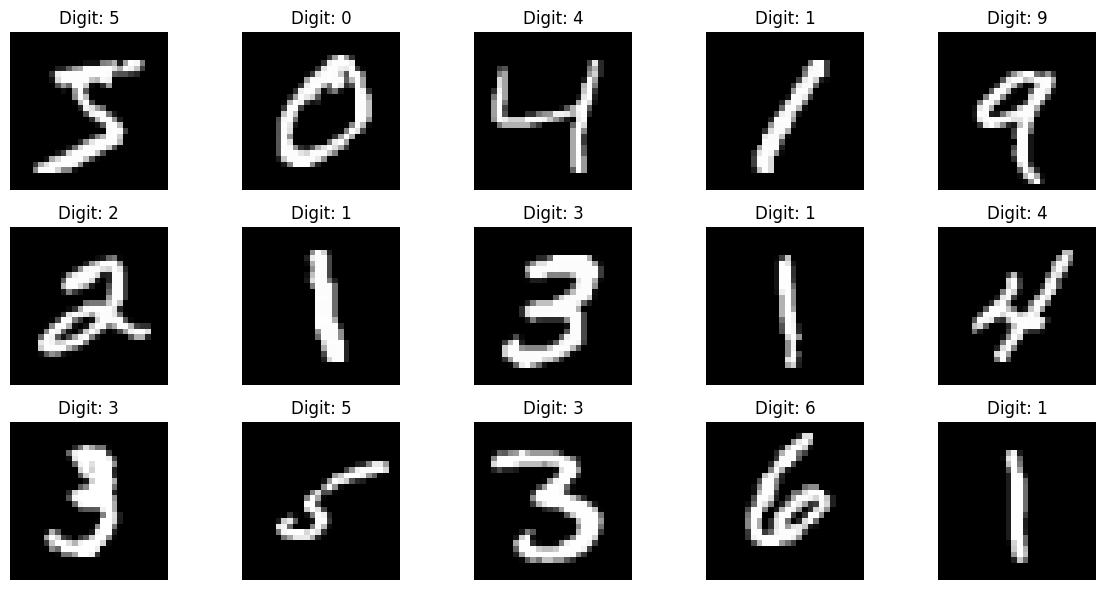

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap='gray')
    plt.title(f"Digit: {y[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
N_SAMPLES = 10000

X_sample = X[:N_SAMPLES]
y_sample = y[:N_SAMPLES]

print("Sample shape:", X_sample.shape)
print("Labels shape:", y_sample.shape)

Sample shape: (10000, 784)
Labels shape: (10000,)


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_sample)

print("Standardized data shape:", X_scaled.shape)

Standardized data shape: (10000, 784)


In [ ]:
pca_50 = PCA(n_components=50, random_state=42)

X_pca_50 = pca_50.fit_transform(X_scaled)

print("Original dimensions:", X_scaled.shape[1])
print("Reduced dimensions:", X_pca_50.shape[1])
print(
    "Explained variance:",
    round(pca_50.explained_variance_ratio_.sum(), 4)
)

Original dimensions: 784
Reduced dimensions: 50
Explained variance: 0.5973


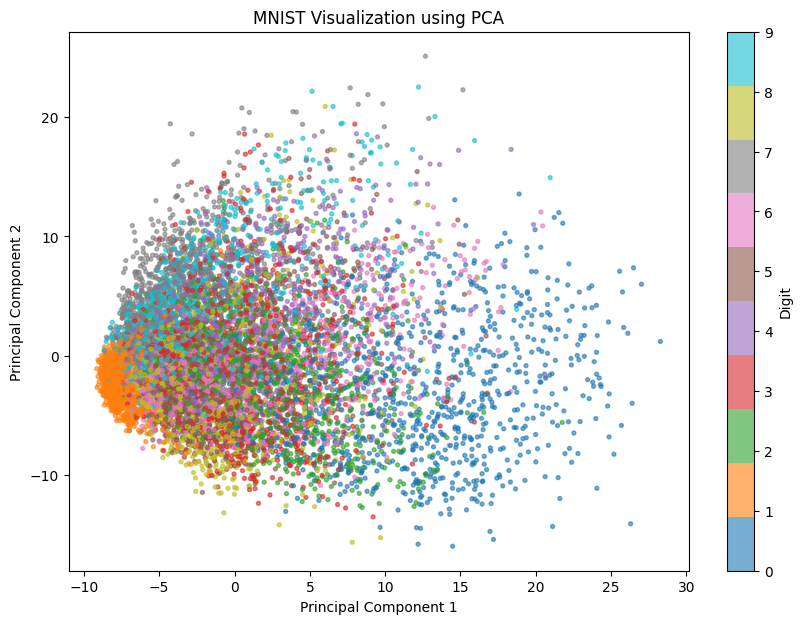

In [ ]:
pca_2 = PCA(n_components=2, random_state=42)

X_pca_2 = pca_2.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca_2[:, 0],
    X_pca_2[:, 1],
    c=y_sample,
    s=8,
    alpha=0.6,
    cmap='tab10'
)

plt.colorbar(scatter, label="Digit")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("MNIST Visualization using PCA")
plt.show()

In [ ]:
TSNE_SAMPLES = 5000

X_tsne_input = X_scaled[:TSNE_SAMPLES]
y_tsne = y_sample[:TSNE_SAMPLES]

start_time = time.time()

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    max_iter=1000
)

X_tsne = tsne.fit_transform(X_tsne_input)

print("t-SNE completed in:",
      round(time.time() - start_time, 2),
      "seconds")

t-SNE completed in: 61.72 seconds


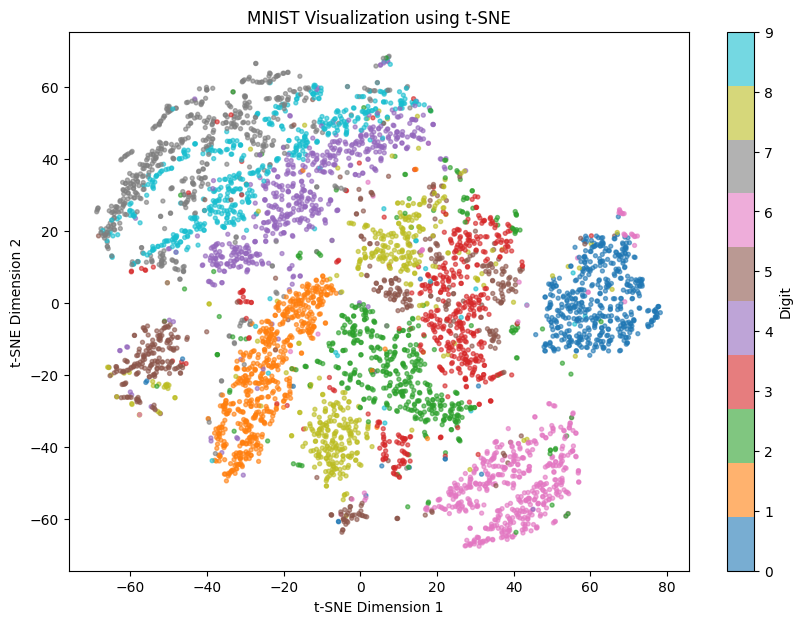

In [ ]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y_tsne,
    s=8,
    alpha=0.6,
    cmap='tab10'
)

plt.colorbar(scatter, label="Digit")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("MNIST Visualization using t-SNE")
plt.show()

In [ ]:
umap_50 = umap.UMAP(
    n_components=50,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

start_time = time.time()

X_umap_50 = umap_50.fit_transform(X_scaled)

print("UMAP completed in:",
      round(time.time() - start_time, 2),
      "seconds")

print("UMAP shape:", X_umap_50.shape)

UMAP completed in: 89.29 seconds
UMAP shape: (10000, 50)


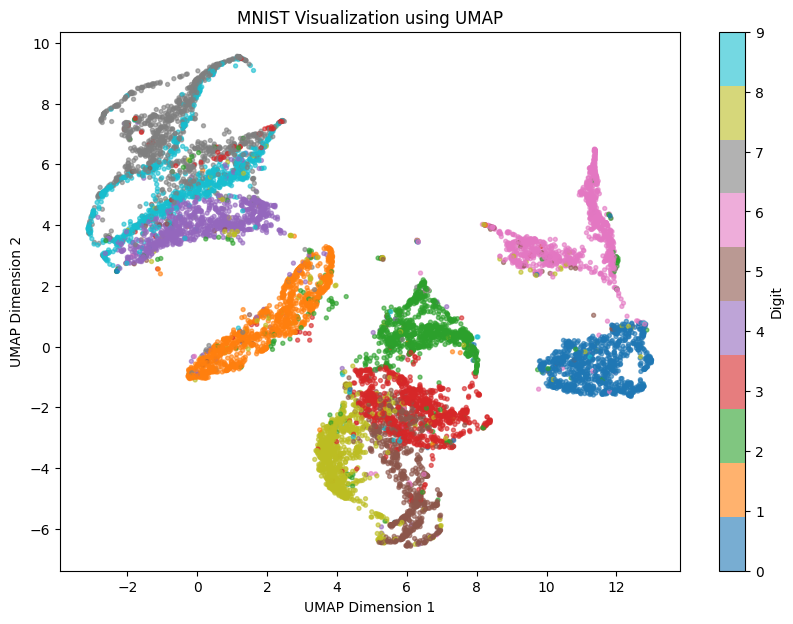

In [ ]:
umap_2 = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

X_umap_2 = umap_2.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_umap_2[:, 0],
    X_umap_2[:, 1],
    c=y_sample,
    s=8,
    alpha=0.6,
    cmap='tab10'
)

plt.colorbar(scatter, label="Digit")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.title("MNIST Visualization using UMAP")
plt.show()

In [ ]:
start_time = time.time()

kmeans = KMeans(
    n_clusters=10,
    init='k-means++',
    n_init=10,
    random_state=42
)

kmeans_labels = kmeans.fit_predict(X_umap_50)

kmeans_time = time.time() - start_time

print("K-Means completed.")
print("Time:", round(kmeans_time, 2), "seconds")

K-Means completed.
Time: 0.83 seconds


In [ ]:
kmeans_ari = adjusted_rand_score(
    y_sample,
    kmeans_labels
)

kmeans_nmi = normalized_mutual_info_score(
    y_sample,
    kmeans_labels
)

kmeans_silhouette = silhouette_score(
    X_umap_50,
    kmeans_labels
)

kmeans_dbi = davies_bouldin_score(
    X_umap_50,
    kmeans_labels
)

print("K-Means Results")
print("----------------")
print("ARI:", round(kmeans_ari, 4))
print("NMI:", round(kmeans_nmi, 4))
print("Silhouette:", round(kmeans_silhouette, 4))
print("Davies-Bouldin:", round(kmeans_dbi, 4))

K-Means Results
----------------
ARI: 0.5144
NMI: 0.6557
Silhouette: 0.4821
Davies-Bouldin: 0.7579


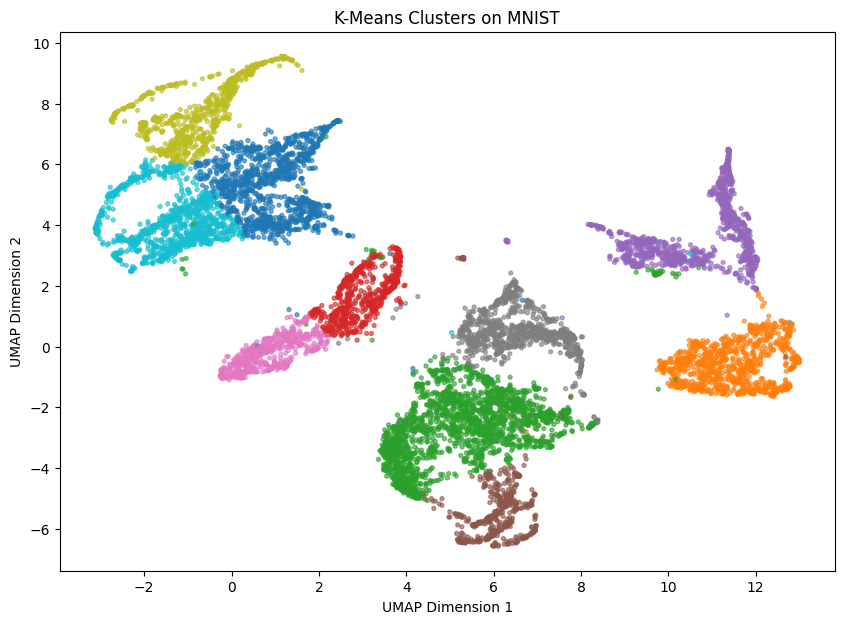

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_umap_2[:, 0],
    X_umap_2[:, 1],
    c=kmeans_labels,
    s=8,
    alpha=0.6,
    cmap='tab10'
)

plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.title("K-Means Clusters on MNIST")
plt.show()

DBSCAN CLUSTERING

In [ ]:
min_samples = 10

In [ ]:
start_time = time.time()

dbscan = DBSCAN(
    eps=2.0,
    min_samples=10,
    n_jobs=-1
)

dbscan_labels = dbscan.fit_predict(X_umap_50)

dbscan_time = time.time() - start_time

print("DBSCAN completed.")
print("Time:", round(dbscan_time, 2), "seconds")

print("Number of clusters:",
      len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))

print("Number of noise points:",
      np.sum(dbscan_labels == -1))

DBSCAN completed.
Time: 1.84 seconds
Number of clusters: 2
Number of noise points: 0


**DBSCAN Evaluation**

In [ ]:
mask = dbscan_labels != -1

dbscan_ari = adjusted_rand_score(
    y_sample,
    dbscan_labels
)

dbscan_nmi = normalized_mutual_info_score(
    y_sample,
    dbscan_labels
)

if len(set(dbscan_labels[mask])) > 1:

    dbscan_silhouette = silhouette_score(
        X_umap_50[mask],
        dbscan_labels[mask]
    )

    dbscan_dbi = davies_bouldin_score(
        X_umap_50[mask],
        dbscan_labels[mask]
    )

else:

    dbscan_silhouette = np.nan
    dbscan_dbi = np.nan

print("DBSCAN Results")
print("----------------")
print("ARI:", round(dbscan_ari, 4))
print("NMI:", round(dbscan_nmi, 4))
print("Silhouette:", round(dbscan_silhouette, 4))
print("Davies-Bouldin:", round(dbscan_dbi, 4))

DBSCAN Results
----------------
ARI: 0.1363
NMI: 0.3472
Silhouette: 0.4609
Davies-Bouldin: 0.7765


**Spectral Clustering**

In [ ]:
SPECTRAL_SAMPLES = 5000

X_spectral = X_umap_50[:SPECTRAL_SAMPLES]
y_spectral = y_sample[:SPECTRAL_SAMPLES]

start_time = time.time()

spectral = SpectralClustering(
    n_clusters=10,
    affinity='nearest_neighbors',
    n_neighbors=10,
    assign_labels='kmeans',
    random_state=42,
    n_jobs=-1
)

spectral_labels = spectral.fit_predict(X_spectral)

spectral_time = time.time() - start_time

print("Spectral Clustering completed.")
print("Time:", round(spectral_time, 2), "seconds")

Spectral Clustering completed.
Time: 3.27 seconds


In [ ]:
spectral_ari = adjusted_rand_score(
    y_spectral,
    spectral_labels
)

spectral_nmi = normalized_mutual_info_score(
    y_spectral,
    spectral_labels
)

spectral_silhouette = silhouette_score(
    X_spectral,
    spectral_labels
)

spectral_dbi = davies_bouldin_score(
    X_spectral,
    spectral_labels
)

print("Spectral Clustering Results")
print("----------------------------")
print("ARI:", round(spectral_ari, 4))
print("NMI:", round(spectral_nmi, 4))
print("Silhouette:", round(spectral_silhouette, 4))
print("Davies-Bouldin:", round(spectral_dbi, 4))

Spectral Clustering Results
----------------------------
ARI: 0.4113
NMI: 0.6211
Silhouette: 0.3768
Davies-Bouldin: 0.7824


In [ ]:
results = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "DBSCAN",
        "Spectral Clustering"
    ],

    "ARI": [
        kmeans_ari,
        dbscan_ari,
        spectral_ari
    ],

    "NMI": [
        kmeans_nmi,
        dbscan_nmi,
        spectral_nmi
    ],

    "Silhouette": [
        kmeans_silhouette,
        dbscan_silhouette,
        spectral_silhouette
    ],

    "Davies-Bouldin": [
        kmeans_dbi,
        dbscan_dbi,
        spectral_dbi
    ],

    "Time (sec)": [
        kmeans_time,
        dbscan_time,
        spectral_time
    ]
})

results

,Algorithm,ARI,NMI,Silhouette,Davies-Bouldin,Time (sec)
0,K-Means,0.514406,0.655724,0.482060,0.757903,0.827845
1,DBSCAN,0.136259,0.347180,0.460943,0.776485,1.844896
2,Spectral Clustering,0.411322,0.621089,0.376818,0.782444,3.267445


**Comparison Graph — ARI**

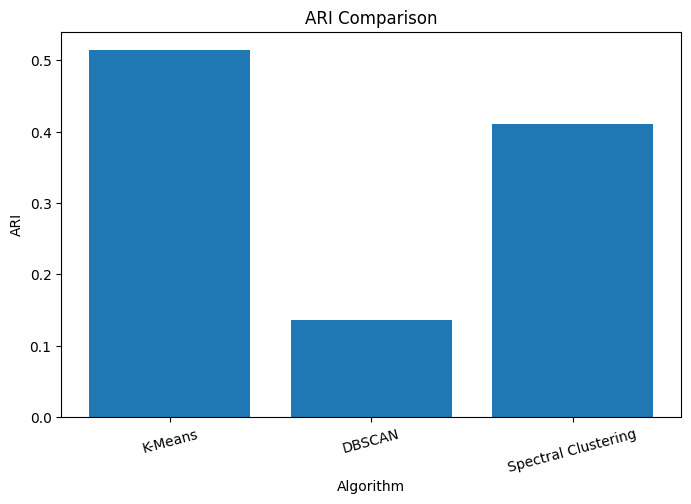

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Algorithm"],
    results["ARI"]
)

plt.ylabel("ARI")
plt.xlabel("Algorithm")
plt.title("ARI Comparison")
plt.xticks(rotation=15)
plt.show()

**NMI Comparison**

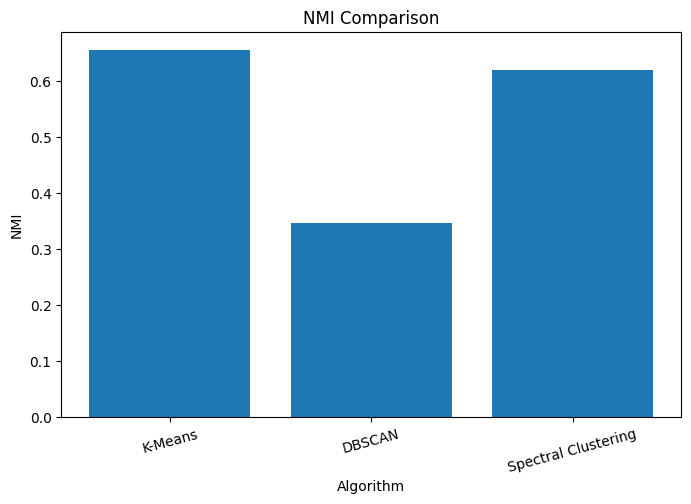

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Algorithm"],
    results["NMI"]
)

plt.ylabel("NMI")
plt.xlabel("Algorithm")
plt.title("NMI Comparison")
plt.xticks(rotation=15)
plt.show()

**Silhouette Comparison**

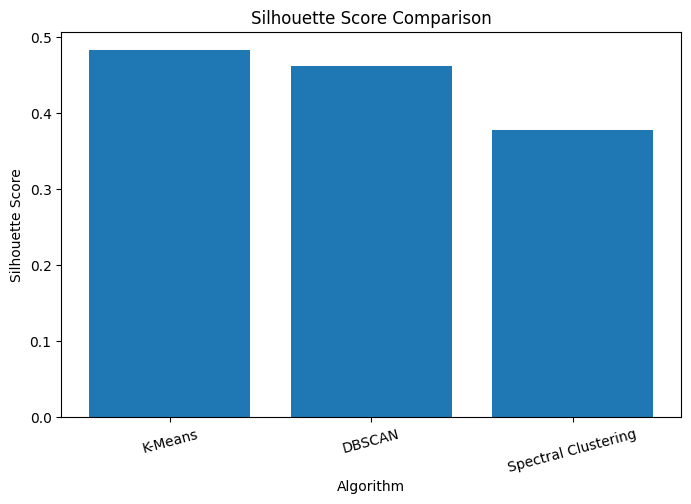

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Algorithm"],
    results["Silhouette"]
)

plt.ylabel("Silhouette Score")
plt.xlabel("Algorithm")
plt.title("Silhouette Score Comparison")
plt.xticks(rotation=15)
plt.show()

**Execution Time Comparison**

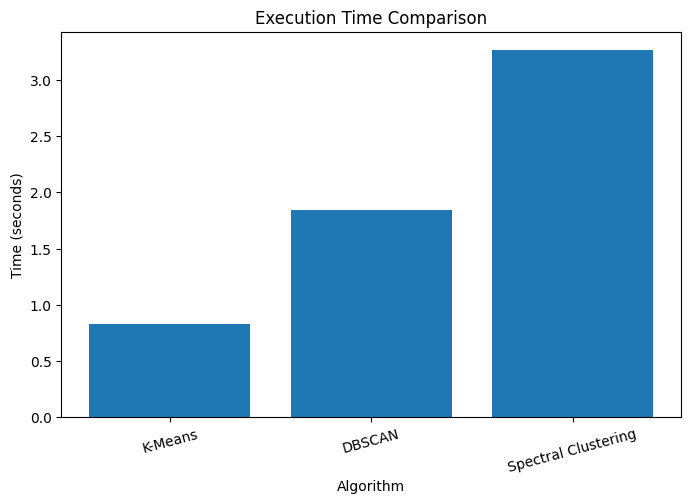

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Algorithm"],
    results["Time (sec)"]
)

plt.ylabel("Time (seconds)")
plt.xlabel("Algorithm")
plt.title("Execution Time Comparison")
plt.xticks(rotation=15)
plt.show()